# Batch 평가 입력

**이 노트북에서 할 일**

1. 07절의 판정 요청 여섯 개를 같은 글로 다시 만듭니다.
2. 요청마다 요청 식별자를 붙여 입력 파일에 한 줄씩 씁니다.
3. 파일을 다시 읽어 네 칸·방식·주소·모델과 겹친 요청 식별자를 검사합니다.
4. 손으로 적은 결과 줄을 요청 식별자로 요청과 잇습니다.

**준비물** — 이 절은 OpenAI API 키를 쓰지 않습니다.
모델 요청과 임베딩 요청이 모두 0번이라 드는 비용이 없습니다.
요청을 보내지 않고, 한꺼번에 맡길 입력 파일만 만드는 절입니다.
파일을 서비스에 올리거나 일괄 작업을 만드는 요청도 보내지 않습니다.

읽는 파일은 이 챕터 자료 파일 하나입니다.
새로 쓰는 파일은 실습 폴더의 `runs/batch-eval-input.jsonl` 하나입니다.
교재 출력을 만든 실행에서는 노트북 전체가 몇 초 안에 끝났습니다.

**기준 버전** — 이 절은 Python에 들어 있는 기능과 도구 파일만 씁니다.
따로 설치할 패키지가 없어 설치 셀을 두지 않았습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~6절을 읽습니다.
07절 요청 글을 다시 만들고, 입력 파일을 쓰고 검사하는 자리입니다.
7절은 결과 줄을 요청 식별자로 잇는 자리입니다.
8절은 값 바꿔 보기이고 7절과 함께 실습 시간에 실행합니다.

실습 폴더 `labs/part4/ch15-evaluation-advanced`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 초록 상자 평가 사례 세 건 이전 판 답 자료 파일과 초록 상자 이후 판 답 둘 Q002 Q090 07절에서 만든 답이 파란 상자 make_prompts 판정 요청 글 여섯 개 07절과 같은 글로 모이고, 파란 상자 make_batch_lines old new 판 표시와 질문 번호로 요청 식별자, 초록 상자 runs/batch-eval-input.jsonl 요청 여섯 줄, 노란 상자 제출 전 검사 네 칸 POST 주소 모델 어긋난 것 없음 겹친 요청 식별자 없음으로 이어진 뒤 점선을 따라 회색 상자 올리기 일괄 작업 만들기 결과 파일 받기 이번에 하지 않음으로 가는 그림](attachment:08-1-판정-요청-여섯-개를-입력-파일로.png)

위에서 아래로 읽습니다. 초록 두 상자의 답으로 판정 요청 글 여섯 개를 만들고, 요청 식별자를 붙여 입력 파일에 씁니다.
노란 상자가 이 절에서 출력으로 확인한 검사이고, 점선 끝 회색 상자는 이 절에서 하지 않은 일입니다.
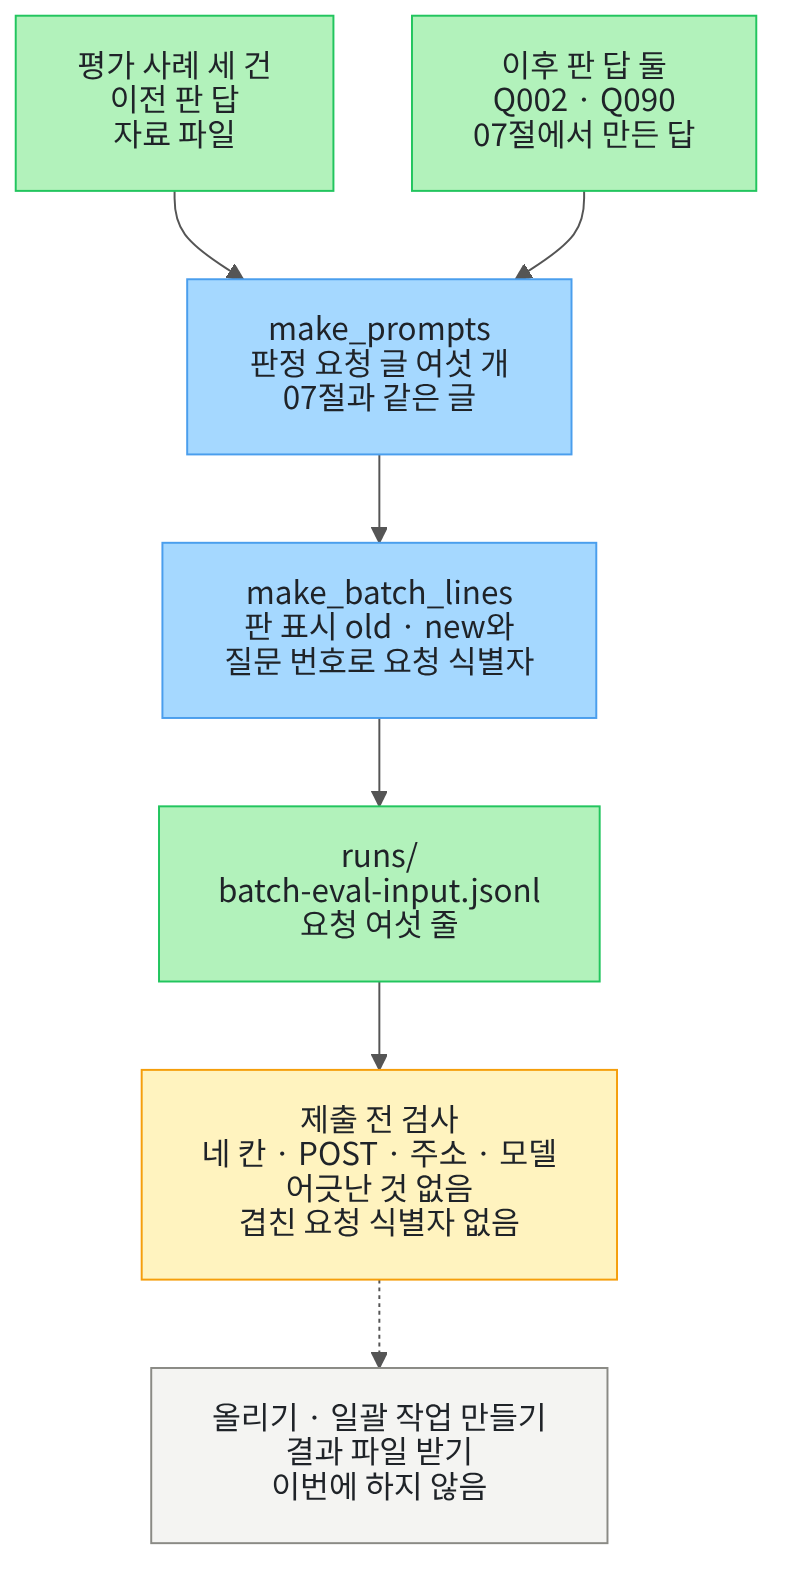

## 1. 준비

이 절은 따로 설치할 패키지가 없습니다.
첫 셀은 이 절에서 쓸 이름을 불러오고 Python 판을 출력합니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 02절 `build_judge_prompt()` 하나만 가져옵니다.

In [1]:
# 입력 파일 쓰기·폴더 확인에 쓸 이름을 불러오고 Python 판을 출력합니다
import json
import os
import platform

# Ch 15 02절 함수 하나를 도구 파일에서 가져옵니다
from rag_tools import build_judge_prompt

print("불러온 이름:", "json", "os", "platform")
print("Python 판:", platform.python_version())

불러온 이름: json os platform
Python 판: 3.12.13


**결과 읽기** — 출력 줄 `Python 판: 3.12.13`이 교재 출력을 만든 판입니다.
이름 `json`은 요청을 JSON 글로 바꿀 때, `os`는 폴더를 찾고 만들 때 씁니다.
도구 파일에서 가져온 함수는 출력하지 않습니다.
이 노트북의 출력은 2026-09-21에 실행한 결과입니다.

다음 셀은 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.
01~07절과 같은 자리 찾기 셀입니다.

In [2]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch15-evaluation-advanced/data"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위:` 뒤에 점 하나나 위로 올라가는 자리가 보입니다.

## 2. 07절 판정 요청 글 다시 만들기

07절은 두 판의 답을 사례 세 건씩 판정해 판정 요청이 여섯 번이었습니다.
요청은 한 번에 하나씩 보냈고, 요청 글은 파일로 남기지 않았습니다.
이 절은 그 여섯 요청을 파일 하나에 담습니다.
먼저 07절과 같은 방법으로 이 챕터 자료 파일을 읽습니다.

In [3]:
# 이 챕터 자료 파일을 읽어 평가 사례 목록을 만들고 질문 번호를 모읍니다(읽기만 합니다)
data_path = root_path + "/labs/part4/ch15-evaluation-advanced/data"
with open(data_path + "/evaluation-cases.json", encoding="utf-8") as file:
    case_file = json.loads(file.read())
cases = case_file["cases"]
case_qids = []
for case in cases:
    case_qids.append(case["qid"])
print("평가 사례 수:", len(cases))
print("질문 번호:", case_qids)

평가 사례 수: 3
질문 번호: ['Q002', 'Q006', 'Q090']


**결과 읽기** — 출력 줄 `평가 사례 수: 3`으로 사례는 세 건입니다.
출력 줄 `질문 번호: ['Q002', 'Q006', 'Q090']`이 입력 파일에 담을 세 사례입니다.

다음 셀은 02절 근거 충실도의 판정 머리글을 다시 적습니다.
07절에서 다시 적은 머리글과 같은 코드입니다.

In [4]:
# 02절 근거 충실도의 두 칸 짝과 판정 머리글 rag-judge-v1.0.0을 다시 적습니다
ground_pair = {"답": "response", "근거 문서": "context"}
ground_rule = "답이 근거 문서로 뒷받침되면 1, 아니면 0을 판정하세요."
output_rule = 'JSON만 출력하세요: {"score": 0 또는 1, "reason": "한 문장"}.'
judge_version = "rag-judge-v1.0.0"
judge_head = ground_rule + "\n" + output_rule
print("판 이름:", judge_version)
print("머리글:")
print(judge_head)

판 이름: rag-judge-v1.0.0
머리글:
답이 근거 문서로 뒷받침되면 1, 아니면 0을 판정하세요.
JSON만 출력하세요: {"score": 0 또는 1, "reason": "한 문장"}.


**결과 읽기** — 출력 줄 `판 이름: rag-judge-v1.0.0`은 02절이 붙인 판 이름입니다.
라벨 줄 `머리글:` 아래 두 줄이 기준 문장과 출력 모양입니다.

다음 셀은 07절 이후 판에서 바뀐 답 두 개를 다시 적습니다.
07절과 같은 코드이고, 두 답은 자료 파일에 없는 07절에서 만든 답입니다.

In [5]:
# 이후 판에서 바뀐 답 두 개를 적습니다(이 절에서 만든 답이고, 나머지 사례의 답은 이전 판 그대로입니다)
new_answers = {}
new_answers["Q002"] = "도서는 한 번에 5권까지 빌릴 수 있고, 대출 기간은 7일입니다. [E01]"
new_answers["Q090"] = "계약서 본문에는 갑과 을 두 회사만 당사자로 적혀 있고 입회인은 적혀 있지 않습니다. 서명면은 스캔본으로 따로 첨부된다고만 적혀 있습니다. [H01]"
changed_qids = list(new_answers.keys())
print("답을 바꾼 사례:", changed_qids)

답을 바꾼 사례: ['Q002', 'Q090']


**결과 읽기** — 출력 줄 `답을 바꾼 사례: ['Q002', 'Q090']`이 이후 판에서 답이 바뀐 두 사례입니다.
사례 Q006의 답은 이후 판에서도 이전 판 그대로입니다.

다음 셀은 07절처럼 사례마다 복사본을 만듭니다.
바뀐 답이 있는 사례만 답 칸을 바꿔 이후 판 사례 목록을 만듭니다.

In [6]:
# 사례마다 복사본을 만들고, 바뀐 답이 있는 사례만 답 칸을 바꿔 이후 판 사례 목록을 만듭니다
new_cases = []
for case in cases:
    new_case = case.copy()
    if case["qid"] in new_answers:
        new_case["response"] = new_answers[case["qid"]]
    new_cases.append(new_case)
print("이후 판 사례 수:", len(new_cases))

이후 판 사례 수: 3


**결과 읽기** — 출력 줄 `이후 판 사례 수: 3`으로 이후 판도 사례 세 건입니다.
원래 목록 `cases`의 답은 그대로 남아 있습니다.

다음 셀은 사례 목록 하나로 판정 요청 글을 모두 만드는 함수입니다.
02절 함수 `build_judge_prompt()`를 사례마다 한 번씩 부릅니다.
모델에 보내지 않고 글만 만듭니다.

In [7]:
# 판정 머리글과 두 칸 짝으로 사례마다 판정 요청 글을 만들어 질문 번호별로 모읍니다(요청은 보내지 않습니다)
def make_prompts(judge_head, pair, case_list):
    prompts = {}
    for case in case_list:
        prompts[case["qid"]] = build_judge_prompt(judge_head, pair, case)
    return prompts

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `make_prompts`는 질문 번호가 키이고 판정 요청 글이 값인 딕셔너리를 만듭니다.
07절 `score_cases()`는 요청 글을 만들어 곧바로 보냈습니다.
이 함수는 글을 모으기만 합니다.

다음 셀은 두 판의 요청 글을 만들고 07절 노트북 5절 출력의 글자 수와 견줍니다.
07절 글자 수는 그 출력에서 옮겨 적은 값입니다.

In [8]:
# 두 판의 판정 요청 글을 만들고, 07절 노트북 5절 출력에 있던 글자 수와 견줍니다
old_prompts = make_prompts(judge_head, ground_pair, cases)
new_prompts = make_prompts(judge_head, ground_pair, new_cases)
old_lengths_07 = {"Q002": 3161, "Q006": 3183, "Q090": 5093}
new_lengths_07 = {"Q002": 3160, "Q006": 3183, "Q090": 5117}
print("질문 번호 | 이전 판 글자 수 | 이후 판 글자 수 | 07절과 같은가")
for qid in case_qids:
    old_length = len(old_prompts[qid])
    new_length = len(new_prompts[qid])
    same = old_length == old_lengths_07[qid] and new_length == new_lengths_07[qid]
    print(qid, "|", old_length, "|", new_length, "|", same)

질문 번호 | 이전 판 글자 수 | 이후 판 글자 수 | 07절과 같은가
Q002 | 3161 | 3160 | True
Q006 | 3183 | 3183 | True
Q090 | 5093 | 5117 | True


**결과 읽기** — 라벨 줄 `질문 번호 | 이전 판 글자 수 | 이후 판 글자 수 | 07절과 같은가` 아래 세 줄이 두 판의 요청 글입니다.
줄 `Q002 | 3161 | 3160 | True`처럼 세 줄 모두 07절 글자 수와 같았습니다.
사례 Q006은 두 판의 답이 같아 요청 글도 `3183`자로 같습니다.

글자 수가 같다고 글이 같다는 보장은 아닙니다.
이 절은 머리글, 두 칸 짝, 바뀐 답을 07절과 같은 코드로 적었습니다.
그래서 여섯 요청 글은 07절이 보낸 요청 글과 같은 글입니다.

## 3. 요청 한 줄의 모양

일괄 처리(Batch API)는 요청 여러 개를 파일 하나에 담아 한꺼번에 맡기는 방식입니다.
결과도 나중에 파일로 받습니다.
사과 바구니 여러 개를 궤짝 하나에 담아 맡기고 나중에 결과를 받는 것과 같습니다.
이 절에서는 판정 요청 여섯 개를 입력 파일 `batch-eval-input.jsonl` 하나에 담습니다.

입력 파일은 Ch 9 06절에서 배운 JSONL 형식이고, 한 줄에 요청 하나를 JSON으로 적습니다.
OpenAI 안내(2026-09-21 확인)에 따르면 한 줄에는 칸 네 개가 들어갑니다.
요청 식별자(`custom_id`), 요청 방식(`method`), 요청 주소(`url`), 요청 본문(`body`)입니다.

OpenAI 안내에 따르면 요청 본문에는 그 요청 주소가 받는 칸을 그대로 적습니다.
02~07절은 `init_chat_model()`에 `temperature=0`과 `reasoning_effort="none"`을 주었습니다.
이 과정의 LangChain 판은 이 설정의 요청을 주소 `/v1/chat/completions`로 보냅니다.

두 설정은 같은 이름의 본문 칸에 들어갑니다. 설치한 판의 소스로 확인했습니다.
다음 셀은 같은 주소와 같은 칸 이름을 적습니다.

In [9]:
# 02~07절 모델 설정과 같은 값을 요청 본문의 칸 이름으로 적고, 요청을 보낼 주소도 적습니다
model_settings = {"model": "gpt-5.4-mini", "temperature": 0, "reasoning_effort": "none"}
request_url = "/v1/chat/completions"
print("본문 설정:", model_settings)
print("요청 주소:", request_url)

본문 설정: {'model': 'gpt-5.4-mini', 'temperature': 0, 'reasoning_effort': 'none'}
요청 주소: /v1/chat/completions


**결과 읽기** — 출력 줄 `본문 설정: {'model': 'gpt-5.4-mini', 'temperature': 0, 'reasoning_effort': 'none'}`이 본문에 넣을 설정 세 칸입니다.
출력 줄 `요청 주소: /v1/chat/completions`가 여섯 요청 모두의 요청 주소입니다.

모델 이름 앞의 `openai:`는 LangChain이 제공자를 고르는 표시라 본문에는 넣지 않습니다.
다음 셀은 요청 한 줄을 만드는 함수입니다.

In [10]:
# 요청 식별자·주소·본문 설정·판정 요청 글로 입력 파일 한 줄에 들어갈 요청 하나를 만듭니다
def make_batch_line(custom_id, url, settings, prompt_text):
    body = settings.copy()
    body["messages"] = [{"role": "user", "content": prompt_text}]
    line = {"custom_id": custom_id, "method": "POST", "url": url, "body": body}
    return line

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `make_batch_line`은 요청 한 줄을 딕셔너리 하나로 만듭니다.
본문은 설정 딕셔너리의 복사본에 메시지 목록을 더한 것입니다.
메시지는 사용자 메시지 하나이고, 내용이 판정 요청 글입니다.

요청 방식은 모든 줄이 `POST`이고, 서버에 내용을 보내 처리를 맡기는 방식입니다.
설치판 소스로 보면 02~07절의 `invoke()`도 같은 주소에 사용자 메시지 하나로 보냈습니다.
다음 셀은 이전 판 Q002 요청 하나를 만들어 칸을 봅니다.

In [11]:
# 이전 판 Q002 요청 하나를 만들어 한 줄의 칸과 본문의 칸을 봅니다(요청은 보내지 않습니다)
one_line = make_batch_line("old-Q002", request_url, model_settings, old_prompts["Q002"])
line_keys = list(one_line.keys())
body_keys = list(one_line["body"].keys())
print("요청 식별자:", one_line["custom_id"])
print("한 줄의 칸:", line_keys)
print("본문의 칸:", body_keys)
print("요청 글 글자 수:", len(one_line["body"]["messages"][0]["content"]))
print("설정 딕셔너리 칸 수:", len(model_settings))

요청 식별자: old-Q002
한 줄의 칸: ['custom_id', 'method', 'url', 'body']
본문의 칸: ['model', 'temperature', 'reasoning_effort', 'messages']
요청 글 글자 수: 3161
설정 딕셔너리 칸 수: 3


**결과 읽기** — 출력 줄 `요청 식별자: old-Q002`가 이 요청의 이름입니다.
출력 줄 `한 줄의 칸: ['custom_id', 'method', 'url', 'body']`가 한 줄의 네 칸입니다.
출력 줄 `본문의 칸: ['model', 'temperature', 'reasoning_effort', 'messages']`처럼 본문에는 설정 세 칸과 메시지 목록이 있습니다.
출력 줄 `요청 글 글자 수: 3161`은 2절 이전 판 Q002 요청 글과 같습니다.

출력 줄 `설정 딕셔너리 칸 수: 3`으로 원래 설정은 그대로입니다.
함수 안에서 `copy()`로 복사본을 만들어 메시지를 더했기 때문입니다.
04절에서 딕셔너리 `copy()`를 쓴 까닭과 같습니다.

## 4. 요청 여섯 줄

요청 식별자(custom_id)는 요청 한 줄마다 붙이는 겹치지 않는 이름입니다.
궤짝에 담은 바구니마다 색이 다른 이름표를 달아 두는 것과 같습니다.
OpenAI 안내에는 결과 파일의 줄 차례가 입력 차례와 다를 수 있다고 적혀 있습니다.
그래서 결과 줄마다 붙어 오는 요청 식별자로 원래 요청을 찾습니다.

이 절은 판 표시와 질문 번호를 이어 요청 식별자를 만듭니다.
이전 판은 `old`, 이후 판은 `new`를 앞에 붙입니다.
다음 셀은 판정 요청 글 모음 하나로 요청 줄 목록을 만드는 함수입니다.

In [12]:
# 판 표시와 질문 번호를 이어 요청 식별자를 붙이고, 판정 요청 글마다 요청 한 줄씩 만듭니다
def make_batch_lines(version_tag, prompts, url, settings):
    lines = []
    for qid in prompts:
        custom_id = version_tag + "-" + qid
        lines.append(make_batch_line(custom_id, url, settings, prompts[qid]))
    return lines

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `make_batch_lines`는 판정 요청 글마다 요청 식별자를 붙여 `make_batch_line()`을 부릅니다.
요청 식별자는 판 표시, 줄표 `-`, 질문 번호를 이어 붙인 글입니다.
요청 줄은 질문 번호 차례대로 목록에 모입니다.

다음 셀은 두 판의 요청 줄을 만들어 한 목록으로 잇습니다.
목록 두 개를 `+`로 이으면 앞 목록 뒤에 뒤 목록을 붙인 새 목록이 됩니다.

In [13]:
# 이전 판에는 old, 이후 판에는 new를 붙여 요청 여섯 줄을 만들고 요청 식별자를 차례로 봅니다
old_lines = make_batch_lines("old", old_prompts, request_url, model_settings)
new_lines = make_batch_lines("new", new_prompts, request_url, model_settings)
batch_lines = old_lines + new_lines
print("요청 수:", len(batch_lines))
print("요청 식별자:")
for line in batch_lines:
    print(line["custom_id"])

요청 수: 6
요청 식별자:
old-Q002
old-Q006
old-Q090
new-Q002
new-Q006
new-Q090


**결과 읽기** — 출력 줄 `요청 수: 6`으로 요청은 여섯 줄입니다.
라벨 줄 `요청 식별자:` 아래 여섯 줄이 요청 식별자이고, `old-Q002`부터 `new-Q090`까지입니다.

사례 Q006은 두 판의 요청 글이 같아 본문도 같습니다.
그래도 요청 식별자가 `old-Q006`과 `new-Q006`으로 달라 두 줄로 따로 들어갑니다.
07절 회귀 스위트처럼 두 판의 사례를 모두 판정하려는 것이라 빼지 않았습니다.

## 5. 입력 파일 쓰기와 다시 읽기

이 챕터에서 파일을 쓰는 것은 이 절이 처음입니다.
Ch 9 06절처럼 요청 하나를 `json.dumps()`로 JSON 글 한 줄로 바꾸고 줄바꿈을 붙입니다.
인자 `ensure_ascii=False`는 한글을 알아볼 수 있는 글자 그대로 적게 합니다.

파일은 `with open(…, "w", encoding="utf-8")`로 엽니다.
이미 있는 파일이면 내용을 지우고 새로 씁니다.
다음 셀은 요청 목록을 JSONL 파일로 쓰는 함수입니다.

In [14]:
# 요청 목록을 받아 요청 하나를 JSON 글 한 줄로 바꿔 파일에 차례로 씁니다(파일이 있으면 새 내용으로 바꿔 씁니다)
def write_jsonl(file_path, lines):
    with open(file_path, "w", encoding="utf-8") as file:
        for line in lines:
            file.write(json.dumps(line, ensure_ascii=False) + "\n")

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `write_jsonl`은 파일 하나를 열고 요청마다 JSON 글 한 줄을 씁니다.
줄마다 끝에 줄바꿈 `\n`을 붙여 요청 하나가 한 줄이 되게 합니다.
들여 쓴 `with` 블록이 끝나면 파일이 닫힙니다.

다음 셀은 실습 폴더의 runs 폴더에 입력 파일을 씁니다.
폴더가 없으면 Ch 9 06절처럼 `os.makedirs()`로 먼저 만듭니다.
쓴 파일은 이름만 출력합니다.

In [15]:
# 실습 폴더의 runs 폴더에 입력 파일을 씁니다(폴더가 없으면 먼저 만듭니다)
runs_path = root_path + "/labs/part4/ch15-evaluation-advanced/runs"
if not os.path.exists(runs_path):
    os.makedirs(runs_path)
batch_path = runs_path + "/batch-eval-input.jsonl"
write_jsonl(batch_path, batch_lines)
print("쓴 파일 이름:", "batch-eval-input.jsonl")
print("파일이 있는가:", os.path.exists(batch_path))

쓴 파일 이름: batch-eval-input.jsonl
파일이 있는가: True


**결과 읽기** — 출력 줄 `쓴 파일 이름: batch-eval-input.jsonl`이 이 절이 쓴 파일입니다.
출력 줄 `파일이 있는가: True`로 파일이 생긴 것을 확인했습니다.
파일은 실습 폴더의 `runs/` 안에 있습니다.

노트북을 다시 실행하면 같은 이름의 파일을 같은 내용으로 새로 씁니다.
요청을 보내지 않고 정한 값만 쓰기 때문입니다.
다음 셀은 JSONL 파일을 읽는 함수입니다.

In [16]:
# JSONL 파일을 읽어 빈 줄을 뺀 줄마다 JSON으로 읽고 딕셔너리 목록을 만듭니다
def read_jsonl(file_path):
    with open(file_path, encoding="utf-8") as file:
        text_lines = file.read().split("\n")
    rows = []
    for text_line in text_lines:
        if text_line != "":
            rows.append(json.loads(text_line))
    return rows

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `read_jsonl`은 파일 글을 줄바꿈으로 나눈 뒤 줄마다 `json.loads()`로 읽습니다.
파일 끝 줄바꿈 뒤에는 빈 글이 하나 남아 `!= ""`로 건너뜁니다.
Ch 9 06절에서 JSONL 파일을 `split("\n")`으로 나눠 읽은 방법과 같습니다.

다음 셀은 방금 쓴 파일을 다시 읽습니다.
쓴 대로 읽히는지 보려면 파일을 다시 읽어 봐야 합니다.

In [17]:
# 방금 쓴 파일을 다시 읽어 줄 수와 첫 줄의 칸을 보고, 쓴 목록과 같은지 견줍니다
loaded_lines = read_jsonl(batch_path)
first_keys = list(loaded_lines[0].keys())
print("다시 읽은 줄 수:", len(loaded_lines))
print("첫 줄의 칸:", first_keys)
print("쓴 목록과 같은가:", loaded_lines == batch_lines)
assert len(loaded_lines) == len(batch_lines)

다시 읽은 줄 수: 6
첫 줄의 칸: ['custom_id', 'method', 'url', 'body']
쓴 목록과 같은가: True


**결과 읽기** — 출력 줄 `다시 읽은 줄 수: 6`으로 파일에는 요청 여섯 줄이 있습니다.
출력 줄 `첫 줄의 칸: ['custom_id', 'method', 'url', 'body']`가 첫 줄의 네 칸입니다.
출력 줄 `쓴 목록과 같은가: True`로 쓴 요청 목록과 읽은 목록이 같습니다.
줄 수는 정한 값에서 나온 결과라 `assert`로도 확인했습니다.

다음 셀은 파일 글을 그대로 읽어 JSONL 한 줄이 어떻게 생겼는지 봅니다.
글의 메서드 `count()`는 괄호 안에 준 글이 몇 번 나오는지 셉니다.

In [18]:
# 파일 글을 그대로 읽어 줄바꿈 수와 첫 줄의 글자 수, 첫 줄의 앞부분을 봅니다
with open(batch_path, encoding="utf-8") as file:
    file_text = file.read()
first_text = file_text.split("\n")[0]
print("줄바꿈 수:", file_text.count("\n"))
print("첫 줄 글자 수:", len(first_text))
print("첫 줄 앞부분:")
print(first_text[:154])

줄바꿈 수: 6
첫 줄 글자 수: 3384
첫 줄 앞부분:
{"custom_id": "old-Q002", "method": "POST", "url": "/v1/chat/completions", "body": {"model": "gpt-5.4-mini", "temperature": 0, "reasoning_effort": "none",


**결과 읽기** — 출력 줄 `줄바꿈 수: 6`으로 파일은 여섯 줄입니다.
출력 줄 `첫 줄 글자 수: 3384`는 첫 줄 전체의 글자 수입니다.
라벨 줄 `첫 줄 앞부분:` 아래는 첫 줄의 앞 154글자이고, 칸 `"messages"` 앞까지입니다.

첫 줄은 요청 글 3161자보다 깁니다.
요청 글 안의 줄바꿈이 파일에서는 `\n` 두 글자로 적히기 때문입니다.
글 안의 큰따옴표도 `\"` 두 글자로 적히고, 칸 이름도 함께 들어갑니다.
그래서 요청 글에 줄바꿈이 있어도 요청 하나는 파일에서 한 줄로 남습니다.

## 6. 제출 전 검사

OpenAI 안내에는 입력 파일 하나에 모델 하나만 쓸 수 있다고 적혀 있습니다.
요청 식별자는 파일 안에서 겹치면 안 된다고도 적혀 있습니다.
이 절은 파일을 올리지 않으므로, 이 두 가지를 우리 코드로 먼저 검사합니다.
다음 셀은 요청 한 줄의 방식·주소·모델이 정한 값과 같은지 보는 함수입니다.

In [19]:
# 요청 한 줄의 방식·주소·모델이 정한 값과 같은지 보고, 어긋난 것의 이름을 목록으로 모읍니다(네 칸이 있는 줄만 넣습니다)
def line_problems(line, url, model_name):
    problems = []
    if line["method"] != "POST":
        problems.append("방식이 POST가 아님")
    if line["url"] != url:
        problems.append("주소가 다름")
    if line["body"]["model"] != model_name:
        problems.append("모델이 다름")
    return problems

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `line_problems`는 방식이 `POST`인지, 주소와 모델이 정한 값과 같은지 봅니다.
어긋난 것이 있으면 그 이름을 목록에 모으고, 없으면 빈 목록 `[]`를 냅니다.
네 칸이 모두 있는 줄만 넣습니다. 칸이 빠진 줄이면 그 칸을 읽는 자리에서 `KeyError`가 납니다.

다음 셀은 다시 읽은 여섯 줄을 한 줄씩 검사합니다.
네 칸의 이름과 차례가 맞는지도 함께 봅니다.

In [20]:
# 다시 읽은 여섯 줄마다 네 칸이 맞는지와 어긋난 것을 보고, 요청 글 글자 수도 봅니다
expected_keys = ["custom_id", "method", "url", "body"]
print("요청 식별자 | 네 칸이 맞는가 | 어긋난 것 | 요청 글 글자 수")
for line in loaded_lines:
    keys_ok = list(line.keys()) == expected_keys
    problems = line_problems(line, request_url, model_settings["model"])
    content = line["body"]["messages"][0]["content"]
    print(line["custom_id"], "|", keys_ok, "|", problems, "|", len(content))

요청 식별자 | 네 칸이 맞는가 | 어긋난 것 | 요청 글 글자 수
old-Q002 | True | [] | 3161
old-Q006 | True | [] | 3183
old-Q090 | True | [] | 5093
new-Q002 | True | [] | 3160
new-Q006 | True | [] | 3183
new-Q090 | True | [] | 5117


**결과 읽기** — 라벨 줄 `요청 식별자 | 네 칸이 맞는가 | 어긋난 것 | 요청 글 글자 수` 아래 여섯 줄이 검사 결과입니다.
줄 `old-Q002 | True | [] | 3161`처럼 여섯 줄 모두 네 칸이 맞고 어긋난 것이 없습니다.
끝 칸의 글자 수는 `3161`부터 `5117`까지 2절 표의 글자 수와 같습니다.

파일에 쓰고 다시 읽어도 요청 글이 바뀌지 않았다는 뜻입니다.
모델도 여섯 줄 모두 같아 입력 파일 하나에 모델 하나라는 조건을 지켰습니다.
다음 셀은 이름 목록에서 두 번 이상 나온 이름을 찾는 함수입니다.

In [21]:
# 이름 목록을 앞에서부터 보며 두 번 이상 나온 이름을 한 번씩만 모읍니다
def duplicate_ids(id_list):
    seen = []
    duplicates = []
    for custom_id in id_list:
        if custom_id in seen and custom_id not in duplicates:
            duplicates.append(custom_id)
        seen.append(custom_id)
    return duplicates

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `duplicate_ids`는 이름을 앞에서부터 보며 이미 본 이름을 목록 `seen`에 모읍니다.
이미 본 이름이 다시 나오면 겹친 이름 목록에 넣습니다.
같은 이름이 세 번 나와도 겹친 이름 목록에는 한 번만 들어갑니다.

다음 셀은 다시 읽은 줄에서 요청 식별자만 모아 겹친 것이 있는지 봅니다.

In [22]:
# 다시 읽은 줄에서 요청 식별자만 모아 겹친 것이 있는지 봅니다(정한 값에서 나온 결과라 assert로 확인합니다)
request_ids = []
for line in loaded_lines:
    request_ids.append(line["custom_id"])
print("요청 식별자 목록:", request_ids)
print("겹친 요청 식별자:", duplicate_ids(request_ids))
assert duplicate_ids(request_ids) == []

요청 식별자 목록: ['old-Q002', 'old-Q006', 'old-Q090', 'new-Q002', 'new-Q006', 'new-Q090']
겹친 요청 식별자: []


**결과 읽기** — 출력 줄 `요청 식별자 목록:` 뒤가 파일 차례대로 모은 요청 식별자 여섯 개입니다.
출력 줄 `겹친 요청 식별자: []`로 겹친 요청 식별자가 없습니다.
정한 값에서 나온 결과라 `assert`로도 확인했습니다.

이 검사를 통과했다고 제출이 성공한다는 뜻은 아닙니다.
판정 결과나 비용도 이 검사로는 알 수 없습니다.
이 절은 입력 파일까지 만들고 제출은 하지 않았습니다.

## 7. 결과를 요청 식별자로 잇기

OpenAI 안내에 따르면 일괄 작업이 끝나면 결과 파일을 따로 받습니다.
결과 파일도 JSONL이고, 성공한 요청 하나가 한 줄입니다.
결과 줄마다 요청 식별자가 들어 있고, 실패한 요청은 오류 파일에 따로 적힙니다.
결과 줄 차례는 입력 차례와 다를 수 있어 요청 식별자로 짝을 찾습니다.

이 절은 제출하지 않아 받은 결과가 없습니다.
그래서 결과 줄 다섯 개의 요청 식별자를 손으로 적어 짝 찾기만 연습합니다.
다음 셀은 첫째 목록에만 있는 이름을 찾는 함수입니다.

In [23]:
# 첫째 목록에는 있고 둘째 목록에는 없는 이름을 첫째 목록 차례대로 모읍니다
def ids_not_in(first_ids, second_ids):
    missing = []
    for custom_id in first_ids:
        if custom_id not in second_ids:
            missing.append(custom_id)
    return missing

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `ids_not_in`은 첫째 목록의 이름 가운데 둘째 목록에 없는 이름을 차례대로 모읍니다.
요청 목록을 첫째로 넣으면 결과가 오지 않은 요청을 찾습니다.
인자 차례를 바꾸면 요청에 없는 결과를 찾습니다. 07절 `broken_cases()`에서 쓴 방법입니다.

다음 셀은 손으로 적은 결과 줄 다섯 개의 요청 식별자로 짝을 찾습니다.
실제로 받은 결과가 아니라 흐름을 보여 주려고 정한 값입니다.

In [24]:
# 손으로 적은 결과 줄 다섯 개의 요청 식별자입니다(실제로 받은 결과가 아니라 흐름을 보여 주려고 정한 값입니다)
result_ids = ["new-Q090", "old-Q002", "new-Q006", "old-Q090", "new-Q002"]
print("결과 줄 수:", len(result_ids))
print("결과 줄 차례:", result_ids)
print("결과가 없는 요청:", ids_not_in(request_ids, result_ids))
print("요청에 없는 결과:", ids_not_in(result_ids, request_ids))
assert ids_not_in(request_ids, result_ids) == ["old-Q006"]
assert ids_not_in(result_ids, request_ids) == []

결과 줄 수: 5
결과 줄 차례: ['new-Q090', 'old-Q002', 'new-Q006', 'old-Q090', 'new-Q002']
결과가 없는 요청: ['old-Q006']
요청에 없는 결과: []


**결과 읽기** — 출력 줄 `결과 줄 수: 5`와 라벨 `결과 줄 차례:` 뒤 목록이 손으로 적은 결과입니다.
출력 줄 `결과가 없는 요청: ['old-Q006']`이 결과 줄이 오지 않은 요청입니다.
출력 줄 `요청에 없는 결과: []`로 모르는 요청 식별자는 없습니다.
손으로 정한 값이라 두 결과를 `assert`로 확인했습니다.

결과 줄은 `new-Q090`부터 적어 입력 차례와 다르게 두었습니다.
차례가 달라도 요청 식별자로 찾으면 빠진 요청을 알 수 있습니다.
실제 결과라면 빠진 요청은 오류 파일에서 찾아봅니다.

다음 셀은 요청 식별자를 판 표시와 질문 번호로 나눠 읽습니다.
글의 `split("-")`는 줄표 자리에서 글을 나눠 목록으로 만듭니다.

In [25]:
# 요청 식별자를 줄표로 나눠 판 표시와 질문 번호를 읽고, 결과 줄이 있는지 입력 차례대로 봅니다
print("판 표시 | 질문 번호 | 결과 줄이 있는가")
for custom_id in request_ids:
    parts = custom_id.split("-")
    print(parts[0], "|", parts[1], "|", custom_id in result_ids)

판 표시 | 질문 번호 | 결과 줄이 있는가
old | Q002 | True
old | Q006 | False
old | Q090 | True
new | Q002 | True
new | Q006 | True
new | Q090 | True


**결과 읽기** — 라벨 줄 `판 표시 | 질문 번호 | 결과 줄이 있는가` 아래 여섯 줄이 입력 차례입니다.
줄 `old | Q006 | False`만 결과 줄이 없고, 나머지 다섯 줄은 `True`입니다.

요청 식별자만 보고도 어느 판의 어느 사례인지 알 수 있습니다.
결과를 사례에 다시 이을 때도 이 두 값으로 짝을 찾습니다.

## 8. 값 바꿔 보기 · 판 표시를 뺀 요청 식별자

바꿀 값은 판 표시 두 개입니다. 이전 판과 이후 판 모두 `judge`를 붙입니다.
두 판의 요청 식별자는 질문 번호로만 갈리게 됩니다.

실행 전에 예상해 봅니다.
두 판의 같은 사례가 같은 요청 식별자를 받아 세 개가 겹칠 것입니다.
이 셀은 요청 목록만 만들고 파일에는 쓰지 않습니다.

In [26]:
# 바꿀 값은 판 표시 두 개입니다: 두 판 모두 judge를 붙여 요청 여섯 줄을 다시 만듭니다(파일에는 쓰지 않습니다)
same_old = make_batch_lines("judge", old_prompts, request_url, model_settings)
same_new = make_batch_lines("judge", new_prompts, request_url, model_settings)
same_ids = []
for line in same_old + same_new:
    same_ids.append(line["custom_id"])
print("요청 식별자 목록:", same_ids)
print("겹친 요청 식별자:", duplicate_ids(same_ids))
assert duplicate_ids(same_ids) == ["judge-Q002", "judge-Q006", "judge-Q090"]

요청 식별자 목록: ['judge-Q002', 'judge-Q006', 'judge-Q090', 'judge-Q002', 'judge-Q006', 'judge-Q090']
겹친 요청 식별자: ['judge-Q002', 'judge-Q006', 'judge-Q090']


**결과 읽기** — 라벨 `요청 식별자 목록:` 뒤 여섯 개에서 `judge-Q002`처럼 같은 이름이 두 번씩 나옵니다.
출력 줄 `겹친 요청 식별자: ['judge-Q002', 'judge-Q006', 'judge-Q090']`이 겹친 세 이름입니다.
마지막 줄의 `assert`도 통과했습니다.

예상대로 세 사례 모두 두 판의 요청 식별자가 겹쳤습니다.
이런 파일은 결과 줄이 와도 어느 판의 판정인지 가를 수 없습니다.
그래서 요청 식별자에는 요청 하나를 가르는 값인 판 표시와 질문 번호를 모두 넣습니다.
겹친 파일을 실제로 올렸을 때 서비스가 어떻게 하는지는 이번에 실행하지 않았습니다.

## 정리

1. 07절 판정 요청 여섯 개를 같은 글로 만들어 입력 파일에 한 줄씩 적었습니다.
2. 네 칸·방식·주소·모델과 겹친 요청 식별자를 제출 전에 검사했습니다.
3. 판 표시를 빼면 요청 식별자 세 개가 겹쳐 결과를 판별로 가를 수 없었습니다.

09절은 이 챕터를 마무리하는 실습 절입니다. 이 입력 파일에서 두 줄씩 골라 평가 모델에 보내고 판정과 예상 비용을 봅니다.